<a href="https://colab.research.google.com/github/Paola21-98/Newton-Raphson/blob/main/CortePaola_Newton_Raphson.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [73]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
print("Hola mundo")

Hola mundo


***Trabajo con la celda 1***
**Qué hace. NumPy, **con el nombre np, permite calcular exponenciales y trabajar con arreglos; pandas, con pd, organiza la tabla; matplotlib.pyplot, con plt, dibuja las gráficas. Importar estas herramientas no resuelve todavía el problema.
Antes de ejecutar:
**¿Qué diferencia hay entre importar una biblioteca y calcular una raíz? **
Importar bibliotecas es usar herramientas para facilitar el uso en Python y calcular la raíz es para encontrar el valor de X de una función.
**¿Cuál de las tres se utilizará para mostrar las iteraciones?**
Import matplotlib.pyplot as plt
Ensayo. Ejecute las tres importaciones. En una celda temporal escriba print(np.exp(0)). Antes de ejecutarla, anticipe el valor de e elevado a cero. Después pruebe print(np.expp(0)).
**¿Qué parte del mensaje permite reconocer el nombre escrito incorrectamente?**
La parte que indica que el módulo numpy no tiene el atributo 'expp'
Para continuar: corrija expp por exp y vuelva a ejecutar. Explique por qué una celda sin salida visible no necesariamente contiene un error. Si aparece un mensaje que indica que np no está definido,
**¿qué celda debe revisar primero? **
Debe revisar la celda 1, donde se importan las bibliotecas.


In [13]:
from __future__ import print_function
def newton_raphson(f, df, x0, tol_f=1e-6, max_iter=50):
  if tol_f <= 0 or max_iter < 1:
    raise ValueError("Revise la tolerancia y el limite de iteraciones.")

  x = float(x0)
  filas = []

  for n in range(max_iter + 1):
    if not np.isfinite(x):
      raise ValueError("La estimacion no es finita.")

    fx = float(f(x))
    dfx = float(df(x))

    if not (np.isfinite(fx) and np.isfinite(dfx)):
      raise ValueError("Funcion o derivada no finita.")

    filas.append([n, x, fx, dfx])

    if abs(fx) <= tol_f:
      columnas = ["n", "x_n", "f(x_n)", "df(x_n)"]
      return x, pd.DataFrame(filas, columns=columnas)

    if n == max_iter:
      break

    if abs(dfx) < 1e-12:
      raise ValueError("Derivada casi nula: cambie x0.")

    x = x - fx / dfx

  raise RuntimeError("No convergio: revise el modelo o x0.")


In [89]:
print(np.exp(0))
print(np.exp(10))

1.0
22026.465794806718


***Trabajo con la celda 2***
Antes de ejecutar: localice la entrada x0, la evaluación f(x), la evaluación df(x), la actualización de x y la salida return. Explique cada una con sus palabras.
**¿Por qué se guarda una fila antes de comprobar la tolerancia?**
Porque así se registra cada aproximación, incluyendo aquella que cumple la tolerancia. De esta manera, la tabla conserva el recorrido completo del método y permite observar cómo se llegó al resultado.
Ensayo de lectura. Ejecute la celda completa.
**¿Se imprime una tabla?**
 No. La celda no imprime una tabla porque únicamente define la función newton_raphson; todavía no realiza ningún cálculo.
 Distinga entre dejar definida una función y llamarla con datos concretos. La primera llamada del café se realizará en la celda 3.
Ensayo de corrección. En una copia temporal del algoritmo quite únicamente los dos puntos al final de la línea def y ejecute. Lea el mensaje, reponga los dos puntos y ejecute otra vez.
**¿Qué diferencia hay entre este error de escritura y que el método no encuentre una raíz?**
El primero es un problema de sintaxis y el segundo es un problema de convergencia numérica
Para continuar: explique qué revisan abs(fx) <= tol_f y abs(dfx) < 1e-12.
**¿Por qué no basta con repetir tres veces?**
Porque tres iteraciones no garantizan que se haya encontrado una solución suficientemente precisa.
El método debe continuar hasta cumplir la tolerancia establecida.
 **¿Qué devuelve el programa si agota el número permitido de actualizaciones?**
Si realiza las actualizaciones permitidas y no consigue cumplir la tolerancia el programa informa que no logró converger y recomienda revisar el modelo matemático o el valor inicial utilizado.
 Los ensayos numéricos de esta función se realizarán con el café.


In [21]:
def f_cafe(t):
    return 60*np.exp(-0.08*t)-20

def df_cafe(t):
    return -4.8*np.exp(-0.08*t)

tiempo, tabla = newton_raphson(f_cafe, df_cafe, 10)
display(tabla.round(6))
print(f"Tiempo: {tiempo:.6f} min")


,n,x_n,f(x_n),df(x_n)
0,0,10.000000,6.959738,-2.156779
1,1,13.226913,0.825778,-1.666062
2,2,13.722559,0.016157,-1.601293
3,3,13.732650,0.000007,-1.600001
4,4,13.732654,0.000000,-1.600000


Tiempo: 13.732654 min


***Trabajo con la celda 3***
**Qué hace. **f_cafe devuelve la diferencia entre la temperatura del modelo y 45 °C; df_cafe indica cómo cambia esa diferencia con el tiempo. La llamada al método guarda la raíz en tiempo y el recorrido en tabla. display muestra la tabla; print presenta el tiempo con seis decimales.
Antes de ejecutar:
**¿Por qué f_cafe contiene −20 si la temperatura buscada es 45 °C?**
Porque se necesita expresar el problema como una ecuación igualada a cero.
**¿La derivada debería ser positiva o negativa?**
Es negativa porque la temperatura del café disminuye conforme pasa el tiempo.
 Calcule la primera actualización con t0 = 10 y compárela con las filas n = 0 y n = 1.
Ensayo. En una celda temporal ejecute newton_raphson(f_cafe, df_cafe, 0) y luego newton_raphson(f_cafe, df_cafe, 20).
**¿Se obtiene aproximadamente el mismo tiempo?**
Sí. Ambos valores iniciales permiten encontrar prácticamente el mismo resultado: 13.732654 minutos.
 Compare la última n de cada tabla, no solo la cantidad de filas: la fila n = 0 es el punto de partida.
Ensayo del límite. Ejecute newton_raphson(f_cafe, df_cafe, 10, max_iter=1).
**¿Qué mensaje obtiene y por qué una sola actualización resulta insuficiente?**
RuntimeError: No convergio: revise el modelo o x0.
 Después compare llamadas con tol_f=1e-2 y tol_f=1e-6.
 **¿Cómo cambian el residuo y las actualizaciones?**
Con tolerancia 10^-2, el programa acepta una aproximación con menor precisión y necesita 3 actualizaciones.
Con tolerancia 10^-6, exige mayor precisión y realiza 4 actualizaciones.
Al disminuir la tolerancia, el residuo final también disminuye.
Para continuar: explique la diferencia entre tiempo y f_cafe(tiempo). Un residuo próximo a cero no significa que el tiempo sea cero. Conserve en la solución final la llamada original, con t0 = 10 y tolerancia 1e-6.



Temperatura comprobada: 45.000000 C
Residuo: 1.066e-12 C


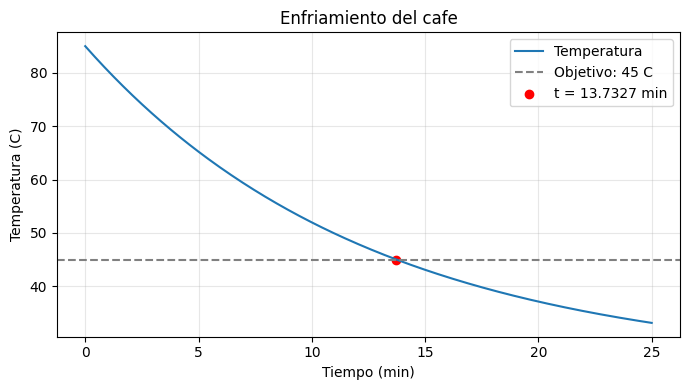

In [23]:
if tiempo < 0:
    raise ValueError("El tiempo debe ser no negativo.")
temperatura = 25 + 60*np.exp(-0.08*tiempo)
print(f"Temperatura comprobada: {temperatura:.6f} C")
print(f"Residuo: {abs(f_cafe(tiempo)):.3e} C")
t = np.linspace(0, 25, 300)
plt.figure(figsize=(7, 4))
plt.plot(t, 25 + 60*np.exp(-0.08*t), label="Temperatura")
plt.axhline(45, color="gray", linestyle="--", label="Objetivo: 45 C")
plt.scatter([tiempo], [45], color="red", label=f"t = {tiempo:.4f} min")
plt.xlabel("Tiempo (min)")
plt.ylabel("Temperatura (C)")
plt.title("Enfriamiento del cafe")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


***Trabajo con la celda 4***
**Qué hace.** Se sustituye el tiempo hallado en T(t) para comprobar la temperatura. np.linspace crea los puntos del eje horizontal; plot dibuja la curva; axhline marca el objetivo; scatter señala la solución. Estas instrucciones representan un resultado ya calculado: no aplican Newton-Raphson.
Antes de ejecutar: **¿qué representa cada eje y dónde debería quedar el punto de solución? **
Eje X (horizontal): representa el tiempo transcurrido en minutos.
Eje Y (vertical): representa la temperatura del café en grados Celsius (°C).
Debe ubicarse donde la curva de enfriamiento alcanza los 45 °C, es decir, donde se cruza con la línea horizontal del objetivo.
 **¿Por qué la comprobación debe dar aproximadamente 45 y el residuo aproximadamente cero?**
La comprobación debe dar aproximadamente 45 °C porque ese es el valor de temperatura que buscamos. El residuo debe ser aproximadamente cero porque representa la diferencia entre la temperatura calculada y la temperatura
Ensayo. En una copia temporal cambie solamente np.linspace(0, 25, 300) por np.linspace(0, 5, 300). El punto calculado puede seguir visible porque scatter amplía el eje, pero la curva quedará dibujada solo hasta cinco minutos.
**¿La ausencia de un cruce en ese tramo permite afirmar que no existe solución**?
No. La ausencia de un cruce entre 0 y 5 minutos no significa que no exista una solución.
Para continuar: restaure el intervalo de 0 a 25. Explique cómo la tabla, la sustitución y la gráfica se complementan. Escriba una conclusión sobre el café sin limitarse a copiar el valor del tiempo e indique que la constante de enfriamiento fue supuesta.


,n,x_n,f(x_n),df(x_n)
0,0,10.000000,188.790205,1256.637061
1,1,9.849766,2.822076,1219.162648
2,2,9.847451,0.000663,1218.589692
3,3,9.847450,0.000000,1218.589557


Radio: 9.847450 cm
Volumen comprobado: 4000.000000 cm^3
Residuo: 3.638e-11 cm^3


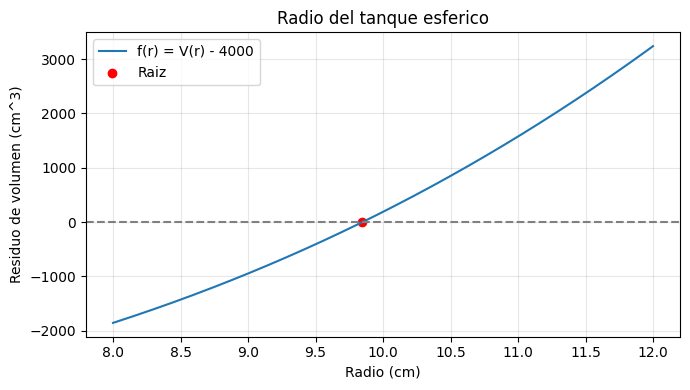

In [18]:
#Celda 5: Tanque esférico
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def f_esfera(r):
    return (4/3)*np.pi*r**3 - 4000
def df_esfera(r):
    return 4*np.pi*r**2
radio, tabla_esfera = newton_raphson(f_esfera, df_esfera, 10)
if radio <= 0:
    raise ValueError("El radio debe ser positivo.")
display(tabla_esfera.round(6))
volumen = (4/3)*np.pi*radio**3
print(f"Radio: {radio:.6f} cm")
print(f"Volumen comprobado: {volumen:.6f} cm^3")
print(f"Residuo: {abs(f_esfera(radio)):.3e} cm^3")
r = np.linspace(8, 12, 300)
plt.figure(figsize=(7, 4))
plt.plot(r, f_esfera(r), label="f(r) = V(r) - 4000")
plt.axhline(0, color="gray", linestyle="--")
plt.scatter([radio], [f_esfera(radio)], color="red", label="Raiz")
plt.xlabel("Radio (cm)")
plt.ylabel("Residuo de volumen (cm^3)")
plt.title("Radio del tanque esferico")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

***Trabajo con la celda 5***
Antes de ejecutar**: explique por qué 4 litros deben convertirse a 4000 cm³ y por qué se busca un radio, no un volumen. Justifique la derivada 4πr².**
Porque debemos trabajar con unidades compatibles. Un litro equivale a 1000 cm³
Porque el volumen ya está establecido en 4000 cm³. Lo que necesitamos determinar es cuánto debe medir el radio interior del tanque para almacenar esa cantidad.
Porque al derivar la función respecto al radio: f'(r)=\frac{4}{3}\pi(3r^2) \]
Simplificando: f'(r)=4\pi r^2 \]
** ¿Qué instrucciones del café se mantienen y cuáles se adaptan al tanque?**
 Se mantienen las importaciones de bibliotecas, la estructura del método Newton-Raphson, la tabla de iteraciones, el cálculo del residuo y la comprobación del resultado.
Se adaptan la función matemática, su derivada, las unidades, el valor inicial y la interpretación del resultado.
En el café se busca el tiempo en minutos; en el tanque se busca el radio en centímetros.
Primera comprobación. Realice las tres actualizaciones manuales con r0 = 10. Después ejecute el código y compare las primeras filas.
**¿El volumen comprobado debe acercarse a cero o a 4000?**
El volumen calculado debe acercarse a 4000 cm³, porque ese es el volumen solicitado.
**¿Qué cantidad sí debe acercarse a cero?**
La cantidad que debe acercarse a cero es el residuo, es decir, la diferencia entre el volumen calculado y el volumen solicitado
Ensayo. En una celda temporal ejecute newton_raphson(f_esfera, df_esfera, 0).
 **¿Por qué se detiene si cero es un número válido en Python? **
El método se detiene porque la derivada en cero también vale cero.
Relacione el mensaje con df_esfera(0) y con el dominio físico. Repita con un valor inicial positivo elegido por usted y compare el recorrido.
Para continuar: vuelva a r0 = 10. **Explique qué significa un residuo positivo o negativo en cm³ y redacte una recomendación de radio interior con su unidad.**
Residuo positivo: el volumen calculado es mayor que 4000 cm³. El tanque tiene más capacidad de la solicitada.
Residuo negativo: el volumen calculado es menor que 4000 cm³. El tanque tiene menos capacidad de la solicitada.
Se recomienda fabricar el tanque esférico con un radio interior aproximado de: 9.85 cm
No cambie el volumen solicitado para hacer coincidir la respuesta.


,n,x_n,f(x_n),df(x_n)
0,0,4.000000,-10.119421,9.035826
1,1,5.119922,-1.524538,6.457361
2,2,5.356015,-0.052737,6.015821
3,3,5.364781,-0.000069,6.000021
4,4,5.364793,-0.000000,6.000000


Tiempo: 5.364793 min
Carga comprobada: 80.000000 %
Residuo: 1.200e-10 puntos porcentuales


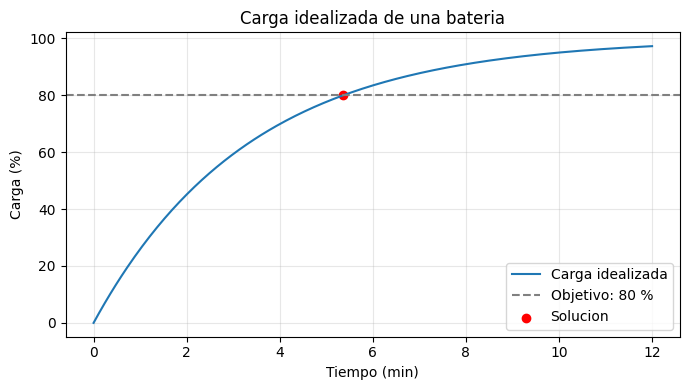

In [28]:
#Celda 6: Batería
def f_bateria(t):
    return 100*(1 - np.exp(-0.30*t)) - 80
def df_bateria(t):
    return 30*np.exp(-0.30*t)
t_bateria, tabla_bateria = newton_raphson(f_bateria, df_bateria, 4)
if t_bateria < 0:
    raise ValueError("El tiempo debe ser no negativo.")
display(tabla_bateria.round(6))
carga = 100*(1 - np.exp(-0.30*t_bateria))
print(f"Tiempo: {t_bateria:.6f} min")
print(f"Carga comprobada: {carga:.6f} %")
print(f"Residuo: {abs(f_bateria(t_bateria)):.3e} puntos porcentuales")
t = np.linspace(0, 12, 300)
plt.figure(figsize=(7, 4))
plt.plot(t, 100*(1 - np.exp(-0.30*t)), label="Carga idealizada")
plt.axhline(80, color="gray", linestyle="--", label="Objetivo: 80 %")
plt.scatter([t_bateria], [carga], color="red", label="Solucion")
plt.xlabel("Tiempo (min)")
plt.ylabel("Carga (%)")
plt.title("Carga idealizada de una bateria")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

***Trabajo con la celda 6***
Antes de ejecutar: **¿qué significa que la carga sea 80 en este modelo?**
Significa que queremos que la batería alcance el 80 % de su capacidad de carga.
**¿Por qué no se escribe 0.80 en el objetivo si C(t) va de 0 a 100? **
Porque la función \(C(t)\) trabaja en una escala de 0 a 100, es decir, representa directamente porcentajes. Por eso, el objetivo correcto es 80 y no 0.80.
**Explique por qué la derivada es positiva, a diferencia del enfriamiento del café.**
La derivada es positiva porque la función exponencial siempre es positiva. Esto significa que la carga de la batería aumenta conforme transcurre el tiempo.
Primera comprobación. Realice tres actualizaciones con t0 = 4. Ejecute la celda y distinga el tiempo calculado, el porcentaje comprobado y el residuo expresado en puntos porcentuales.
**¿Por qué la curva crece mientras la del café disminuye?**
Porque representan fenómenos diferentes. La batería acumula carga eléctrica conforme pasa el tiempo, mientras que el café pierde energía térmica y disminuye su temperatura.
Ensayo. Ejecute en celdas temporales newton_raphson(f_bateria, df_bateria, 0) y newton_raphson(f_bateria, df_bateria, 8). Anticipe si cambiará el tiempo final o solo el recorrido y contraste su previsión con las tablas. Si aparece un error, registre el mensaje antes de corregir.
Para continuar: conserve t0 = 4. Identifique las instrucciones que comprueban el resultado y las que solo lo dibujan.
**Explique por qué obtener un tiempo matemáticamente válido no permite asegurar que cualquier teléfono cargará así. **
Este resultado no garantiza que cualquier teléfono cargue en ese tiempo, porque la velocidad real depende de la capacidad de la batería, el cargador, el dispositivo y las condiciones de carga.

,n,x_n,f(x_n),df(x_n)
0,0,0.050000,-42.246875,2315.250000
1,1,0.068247,1.114083,2438.065163
2,2,0.067790,0.000715,2434.937779
3,3,0.067790,0.000000,2434.935771


Tasa decimal: 0.06778997
Tasa efectiva anual: 6.778997 %
Monto comprobado: USD 650.000000
Residuo: USD 2.948e-10


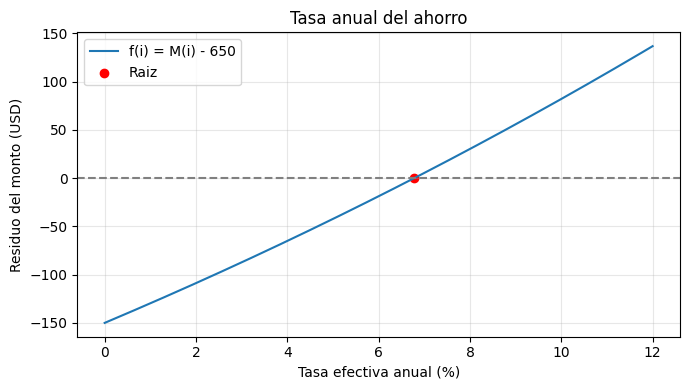

In [31]:
#Celda 7: Ahorro
def f_ahorro(i):
    return 500*(1 + i)**4 - 650
def df_ahorro(i):
    return 2000*(1 + i)**3
tasa, tabla_ahorro = newton_raphson(f_ahorro, df_ahorro, 0.05)
if tasa < 0:
    raise ValueError("La tasa debe ser no negativa en este ejercicio.")
display(tabla_ahorro.round(6))
monto = 500*(1 + tasa)**4
print(f"Tasa decimal: {tasa:.8f}")
print(f"Tasa efectiva anual: {100*tasa:.6f} %")
print(f"Monto comprobado: USD {monto:.6f}")
print(f"Residuo: USD {abs(f_ahorro(tasa)):.3e}")
i = np.linspace(0, 0.12, 300)
plt.figure(figsize=(7, 4))
plt.plot(100*i, f_ahorro(i), label="f(i) = M(i) - 650")
plt.axhline(0, color="gray", linestyle="--")
plt.scatter([100*tasa], [f_ahorro(tasa)], color="red", label="Raiz")
plt.xlabel("Tasa efectiva anual (%)")
plt.ylabel("Residuo del monto (USD)")
plt.title("Tasa anual del ahorro")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


***Trabajo con la celda 7***
Antes de ejecutar: identifique el capital, el monto, el plazo y la incógnita. }
Identificamos los elementos:
Elemento	         Valor
Capital inicial	   500
Monto objetivo	   Monto establecido en el código
Plazo	             4 años
Incógnita       	 Tasa de interés anual \(i\)
Valor inicial    	 0.05

**¿Por qué el valor inicial es 0.05 y no 5? **
Porque las tasas de interés se expresan en forma decimal para realizar los cálculos matemáticos.
**Explique el factor 2000 de la derivada y la diferencia entre tasa decimal y tasa porcentual.**
El factor 2000 aparece al multiplicar el capital de 500 por el plazo de cuatro años.
Ensayo de unidades. En una celda temporal evalúe print(500*(1+0.05)**4) y print(500*(1+5)**4).
**¿Qué tasa representa cada expresión?**
 L a primera representa una tasa del 5 % anual durante cuatro años.
La segunda representa una tasa del 500 % anual.
**¿Por qué un programa puede ejecutar sin errores y aun así utilizar datos mal interpretados?**
Porque Python realiza las operaciones matemáticas correctamente, pero no reconoce automáticamente si una tasa está expresada en porcentaje o en decimal.
Ensayo del método. Tras las tres actualizaciones manuales con i0 = 0.05, pruebe newton_raphson(f_ahorro, df_ahorro, 0.02) y newton_raphson(f_ahorro, df_ahorro, 0.10). Compare la tasa, el residuo y la última n. Mantenga sin cambios el capital y el monto objetivo.
Para continuar: restaure i0 = 0.05. Explique por qué la gráfica usa 100*i, pero la fórmula del monto usa i **texto en negrita**.  
Porque la gráfica presenta la tasa en porcentaje para facilitar su interpretación visual. En cambio, la fórmula del interés compuesto necesita la tasa en forma decimal para realizar correctamente las operaciones.
**Redacte la conclusión indicando tasa efectiva anual, plazo y monto comprobado; no confunda la tasa anual con el aumento total de los cuatro años.**
El método de Newton-Raphson permite encontrar la tasa de interés efectiva anual necesaria para alcanzar un monto objetivo a partir de un capital inicial de 500 durante cuatro años. Es importante ingresar la tasa en forma decimal y no porcentual, ya que esto evita errores en los cálculos. Además, el valor inicial influye en el proceso de convergencia del método. Finalmente, la tasa anual no representa el aumento total acumulado durante los cuatro años, sino el porcentaje de crecimiento aplicado cada año.
